In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import nuels_fun_with_peptides as nfp

protein_map = nfp.read_fasta("../data/sample_proteins.fasta")                   #change here to your own pathway

protein_map

{'P11802': 'MATSRYEPVAEIGVGAYGTVYKARDPHSGHFVALKSVRVPNGGGGGGGLPISTVREVALLRRLEAFEHPNVVRLMDVCATSRTDREIKVTLVFEHVDQDLRTYLDKAPPPGLPAETIKDLMRQFLRGLDFLHANCIVHRDLKPENILVTSGGTVKLADFGLARIYSYQMALTPVVVTLWYRAPEVLLQSTYATPVDMWSVGCIFAEMFRRKPLFCGNSEADQLGKIFDLIGLPPEDDWPRDVSLPRGAFPPRGPRPVQSVVPEMEESGAQLLLEMLTFNPHKRISAFRALQHSYLHKDEGNPE',
 'A0A087WTH1': 'MEDEEKAVEILGNTEAAHPPSPIRCCWLRLRCLAATSIICGCSCLGVMALVFAIKAEERHKAGRSEEAVRWGARARKLILASFAVWLAVLILGPLLLWLLSYAIAQAPEPTIDERE',
 'A0A087WTH5': 'MVIEWERPRMILSNTTAVTPFLTKLWQETVQQGGNMSGLARRSPRSGDGKLEALYVLMVLGFFGFFTLGIMLSYIRSKKLEHSNDPFNVYIESNAWQEKDKAYVQARVLESYRSCYVVENHLAIEQPNTHLPETKPSP'}

In [3]:
from nuels_fun_with_peptides.variables import enzyme_cleavage_patterns
cleavege_pattern = enzyme_cleavage_patterns['LysC']                             #change/edit the library and the enzyme

nfp.digest_protein_sequence(protein_map["P11802"], cleavege_pattern)

['MATSRYEPVAEIGVGAYGTVYK',
 'ARDPHSGHFVALK',
 'VTLVFEHVDQDLRTYLDK',
 'APPPGLPAETIK',
 'DLMRQFLRGLDFLHANCIVHRDLK',
 'PENILVTSGGTVK',
 'PLFCGNSEADQLGK',
 'RISAFRALQHSYLHK',
 'DEGNPE']

In [4]:
digested_peptide_map = nfp.digest_protein_collection(protein_map,
    cleave_pattern=cleavege_pattern,
    min_pep_len=5,
    max_pep_len=30,
)

In [5]:
nfp.compute_sequence_coverage(protein_map["P11802"], digested_peptide_map["P11802"])

45.21452145214522

In [6]:
digested_peptide_list = sum(digested_peptide_map.values(), [])                  #make sure youre input is a list

retention_time_map = nfp.predict_lc_retention_times(digested_peptide_list)

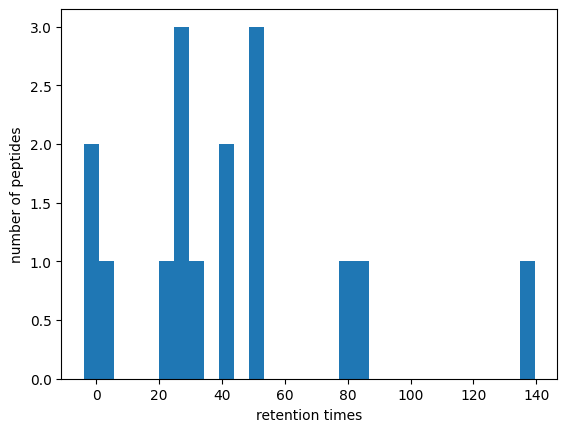

In [8]:
nfp.plot_retention_time(retention_time_map)

In [9]:
select_peps = nfp.select_retention_time_window(
    peptide_rt_map=retention_time_map,
    lower_ret_time=0,
    upper_ret_time=50,
)

select_peps

['ARDPHSGHFVALK',
 'APPPGLPAETIK',
 'PENILVTSGGTVK',
 'PLFCGNSEADQLGK',
 'RISAFRALQHSYLHK',
 'AEERHK',
 'AGRSEEAVRWGARARK',
 'LWQETVQQGGNMSGLARRSPRSGDGK',
 'LEHSNDPFNVYIESNAWQEK']